# XXZ模型：基底エネルギー$E_0$

基底エネルギー$E_0$を、厳密対角化・Bethe仮説・VQEの3つの手法で求めて比較する。模型の定義は [00_model.ipynb](00_model.ipynb)、各手法のXXZ模型への適用は [01_exact_diag](01_exact_diag.ipynb)・[02_jordan_wigner](02_jordan_wigner.ipynb)（Jordan-Wigner変換とBethe仮説）・[03_trotter](03_trotter.ipynb)・[04_vqe](04_vqe.ipynb)、手法の一般論は [methods/](../../methods/) を参照。

TFIMではJordan-Wigner変換が厳密対角化の答え合わせと大きな$n$の計算を担ったが、XXZ模型ではその役割を**Bethe仮説**が担う。Bethe仮説は周期境界条件で使うので、1〜3節は周期境界条件で計算する。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb
from scipy.sparse.linalg import eigsh

# 厳密対角化（src/qmb/ed.py）と XXZ 模型の定義（src/qmb/models.py）
from qmb.ed import ground_state
from qmb.models import xxz_hamiltonian as hamiltonian, xxz_hamiltonian_sector

# 各手法の XXZ 模型への適用（src/qmb/models.py, circuits.py）
#   xxz_bethe_ground_state : Bethe 方程式を解いて E0 を求める（周期境界）
#   xxz_e0_thermodynamic   : 熱力学極限の e0 = lim E0/n
#   xxz_vqe                : 一重項から始める HVA の VQE
from qmb.models import xxz_bethe_ground_state as ground_energy_bethe, xxz_e0_thermodynamic
from qmb.circuits import xxz_vqe
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: xxz_bethe_ground_state??）


def ground_energy_ed(n, J, Delta, pbc=True):
    # 全磁化 0（m = n/2）のブロックを疎行列で作り、最小固有値だけを Lanczos 法で求める
    return eigsh(xxz_hamiltonian_sector(n, J, Delta, n // 2, pbc=pbc), k=1, which="SA")[0][0]

## 1. 厳密対角化とBethe仮説の比較

$n=4$から$18$まで、厳密対角化（全磁化0のブロック、$\binom{n}{n/2}$次元の疎行列）とBethe仮説（$n/2$変数の連立方程式）で$E_0$を求め、差と計算時間を比べる。

 n   ブロックの次元  E0 (ED)            E0 (Bethe)         差
 4             6  -6.744562646538  -6.744562646538  8.9e-16
 6            20  -9.472135955000  -9.472135955000  3.6e-15
 8            70  -12.347977420550  -12.347977420550  3.6e-15
10           252  -15.276131122066  -15.276131122066  3.6e-15
12           924  -18.229089763322  -18.229089763322  7.1e-15
14          3432  -21.195834008070  -21.195834008070  4.3e-14
16         12870  -24.171053272714  -24.171053272714  1.1e-14


18         48620  -27.151862808228  -27.151862808228  3.6e-14


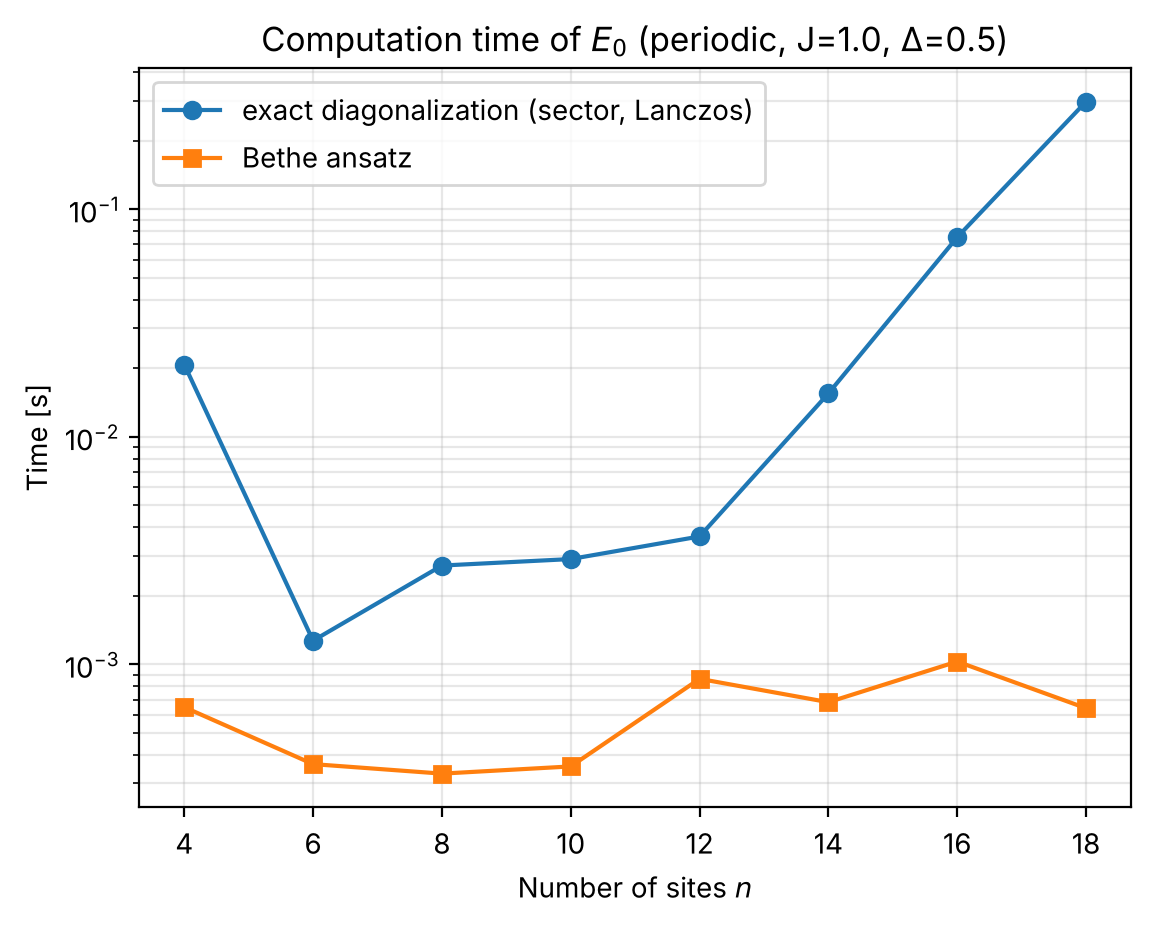

In [2]:
import time

J = 1.0
Delta = 0.5
ns = list(range(4, 19, 2))
t_ed, t_b = [], []
print(" n   ブロックの次元  E0 (ED)            E0 (Bethe)         差")
for n in ns:
    start = time.perf_counter()
    E_ed = ground_energy_ed(n, J, Delta)
    t_ed.append(time.perf_counter() - start)

    start = time.perf_counter()
    E_b = ground_energy_bethe(n, J, Delta)[0]
    t_b.append(time.perf_counter() - start)
    print(f"{n:2d}  {comb(n, n // 2):12d}  {E_ed:.12f}  {E_b:.12f}  {abs(E_ed - E_b):.1e}")

plt.semilogy(ns, t_ed, "o-", label="exact diagonalization (sector, Lanczos)")
plt.semilogy(ns, t_b, "s-", label="Bethe ansatz")
plt.xlabel("Number of sites $n$")
plt.ylabel("Time [s]")
plt.title(f"Computation time of $E_0$ (periodic, J={J}, Δ={Delta})")
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.show()

2つの手法の$E_0$は数値誤差の範囲で一致している。厳密対角化はブロックと疎行列を使っても$n$とともに指数関数的に時間が増えるが、Bethe仮説はほとんど増えない。

## 2. 大きな$n$と熱力学極限

Bethe仮説なら大きな$n$も計算できるので、1サイトあたりのエネルギー$E_0/n$が$n\to\infty$でどこに近づくかを調べる。[methods/06_bethe_ansatz.ipynb](../../methods/06_bethe_ansatz.ipynb)の9節の積分方程式をフーリエ変換で解くと、熱力学極限の値は次のようになる（Hulthén 1938、Yang-Yang 1966。$J$はこのリポジトリのPauli演算子の規約で、スピン演算子の規約の$4$倍）。

\begin{equation}
e_0 = \lim_{n\to\infty}\frac{E_0}{n} =
\begin{cases}
J\left[\Delta - 2\sin\gamma\displaystyle\int_{-\infty}^{\infty}\frac{\sinh((\pi-\gamma)x)}{\sinh(\pi x)\cosh(\gamma x)}dx\right] & (-1<\Delta = \cos\gamma<1) \\[3mm]
J(1 - 4\ln2) & (\Delta = 1) \\[2mm]
J\left[\Delta - 4\sinh\eta\left(\dfrac12 + 2\displaystyle\sum_{m=1}^{\infty}\frac{1}{e^{2m\eta} + 1}\right)\right] & (\Delta = \cosh\eta>1)
\end{cases}
\end{equation}

特に$\Delta=0$では$e_0 = -4J/\pi$（自由フェルミオンの値）、$\Delta = 1/2$では$e_0 = -3J/2$である。

- **有限サイズ補正**：$-1<\Delta\le1$はギャップのない臨界相で、共形場理論から周期境界条件では
  \begin{equation}
  \frac{E_0}{n} \approx e_0 - \frac{\pi c\,v}{6n^2},\qquad c = 1,\quad v = \frac{2\pi J\sin\gamma}{\gamma}
  \end{equation}
  となる（$c$は中心電荷、$v$は素励起（スピノン）の速さ。$\Delta=1$では$v = 2\pi J$）。$\Delta>1$はギャップのある相で、補正は$n$について指数関数的に小さい。

Δ     e0 (積分公式)    E0/n (n=1000, Bethe)   n^2 (E0/n - e0) (n=1000)   -πcv/6 (c=1)


0.0  -1.273239544735  -1.273241639133       -2.094398              -2.094395


0.5  -1.500000000000  -1.500002720704       -2.720704              -2.720699


1.0  -1.772588722240  -1.772592014015       -3.291775              -3.289868


2.0  -2.468888183903  -2.468888183903       -0.000000                    nan


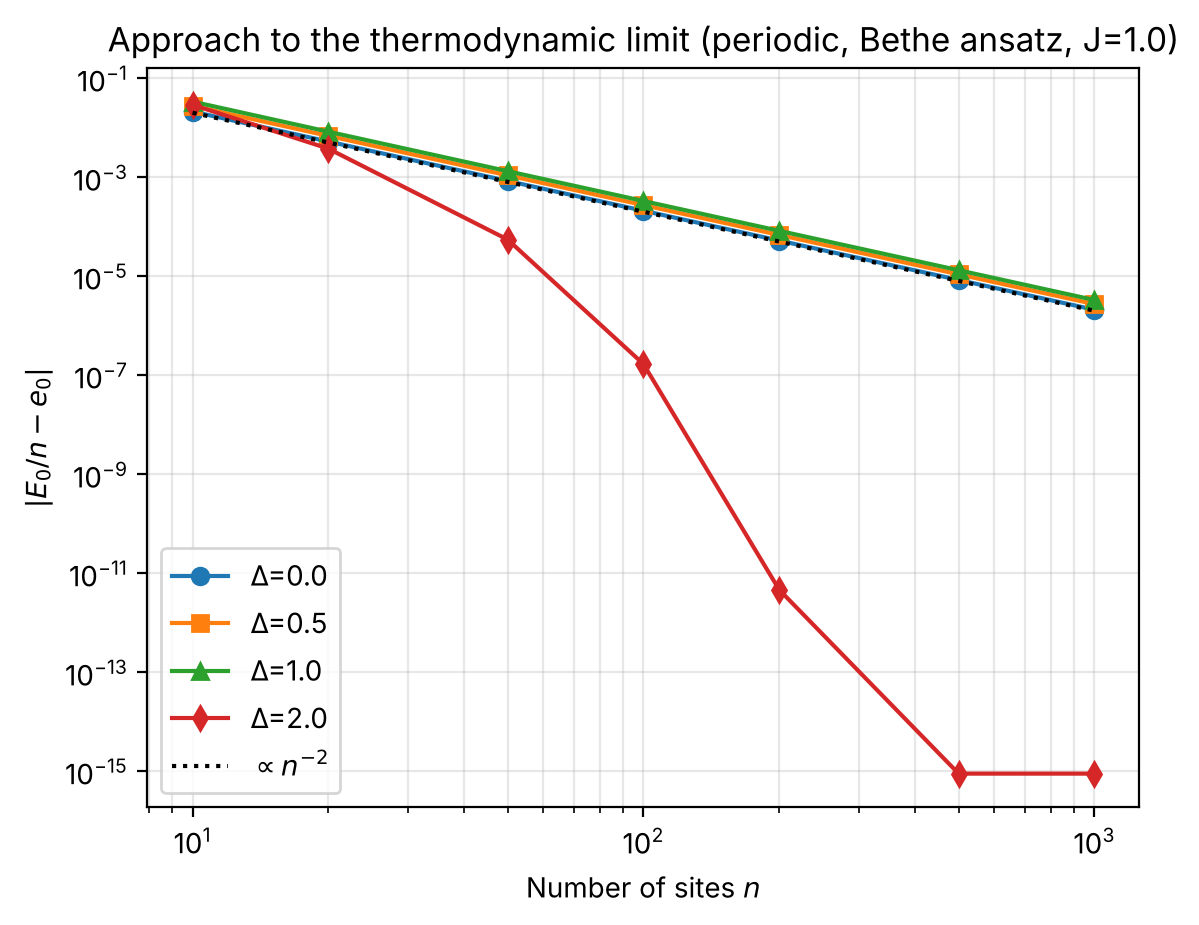

In [3]:
J = 1.0
ns = np.array([10, 20, 50, 100, 200, 500, 1000])
print("Δ     e0 (積分公式)    E0/n (n=1000, Bethe)   n^2 (E0/n - e0) (n=1000)   -πcv/6 (c=1)")
for Delta, mk in [(0.0, "o-"), (0.5, "s-"), (1.0, "^-"), (2.0, "d-")]:
    e0 = xxz_e0_thermodynamic(J, Delta)
    e_n = np.array([ground_energy_bethe(n, J, Delta)[0] / n for n in ns])
    if Delta < 1:
        gamma = np.arccos(Delta)
        cft = -np.pi * (2 * np.pi * J * np.sin(gamma) / gamma) / 6
    elif Delta == 1:
        cft = -np.pi * (2 * np.pi * J) / 6
    else:
        cft = np.nan
    print(f"{Delta:3.1f}  {e0:.12f}  {e_n[-1]:.12f}      {ns[-1]**2 * (e_n[-1] - e0):10.6f}              {cft:9.6f}")
    plt.loglog(ns, np.abs(e_n - e0), mk, label=f"Δ={Delta}")
plt.loglog(ns, 2 / ns**2, "k:", label=r"$\propto n^{-2}$")
plt.xlabel("Number of sites $n$")
plt.ylabel(r"$|E_0/n - e_0|$")
plt.title(f"Approach to the thermodynamic limit (periodic, Bethe ansatz, J={J})")
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.show()

$-1<\Delta\le1$では$|E_0/n - e_0|$が$n^{-2}$に比例して0に近づき、$n^2(E_0/n - e_0)$は共形場理論の予言$-\pi cv/6$（$c=1$）とよく一致する。XXZ模型の臨界相が$c=1$の共形場理論（朝永-Luttinger液体）で記述されることを、エネルギーだけから確かめられた。$\Delta=1$では一致が少し遅いが、これはSU(2)対称性による対数的な補正があるためである。$\Delta=2$では$n=20$程度で誤差が数値誤差の大きさまで一気に小さくなり、ギャップのある相の指数関数的な収束になっている。

TFIMの開放境界条件では補正が$1/n$（端の寄与）だったが、ここでは周期境界条件なので端がなく、$1/n^2$の補正が主になる。

## 3. 異方性$\Delta$への依存性

$e_0$を$\Delta$の関数として描き、Bethe仮説（$n=200$）と厳密対角化（$n=16$）と比べる。

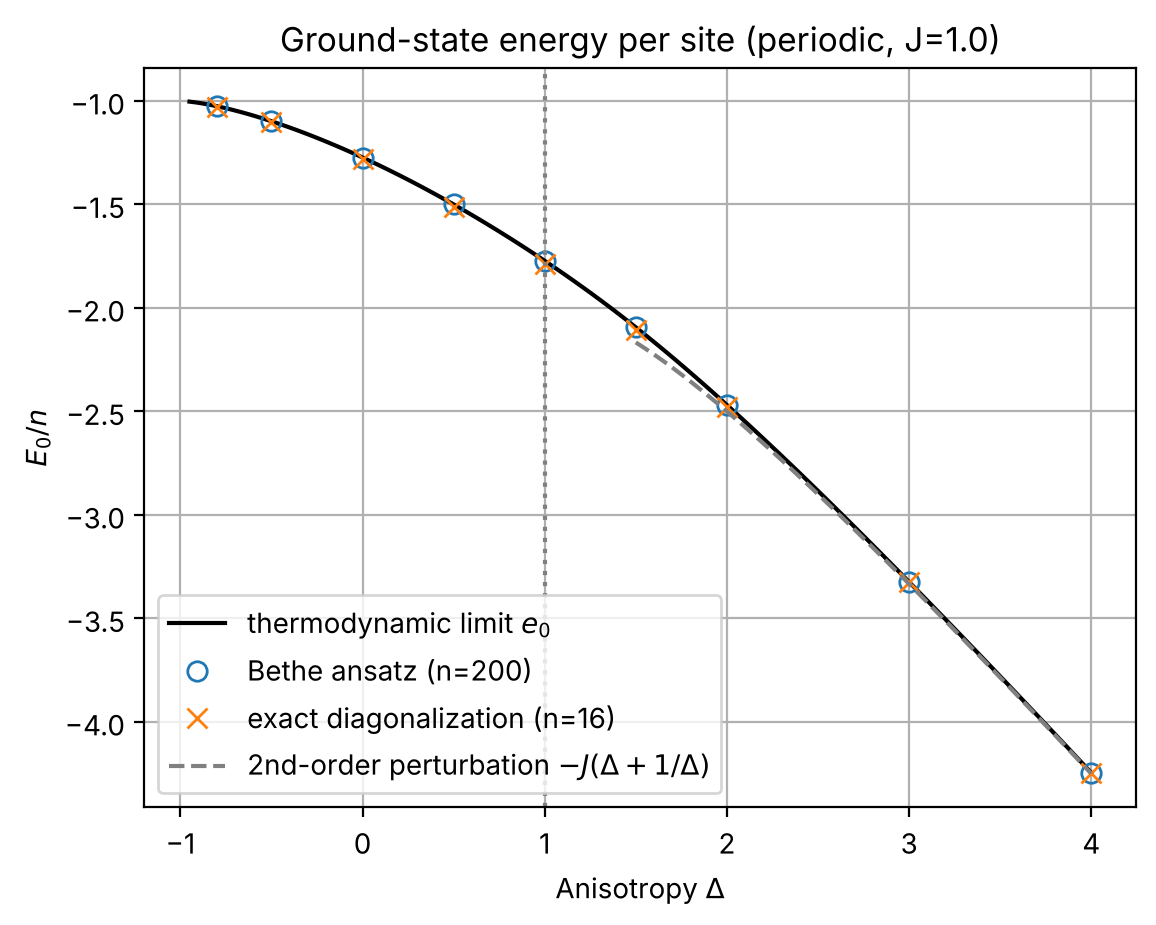

Δ=0.0: e0 = -1.2732395447  (-4/π)
Δ=0.5: e0 = -1.5000000000  (-3/2)
Δ=1.0: e0 = -1.7725887222  (1 - 4 ln 2)


In [4]:
J = 1.0
D_curve = np.concatenate([np.linspace(-0.95, 0.99, 60), [1.0], np.linspace(1.01, 4.0, 60)])
plt.plot(D_curve, [xxz_e0_thermodynamic(J, D) for D in D_curve], "k-", label=r"thermodynamic limit $e_0$")

D_pts = [-0.8, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
plt.plot(D_pts, [ground_energy_bethe(200, J, D)[0] / 200 for D in D_pts], "o", ms=7, mfc="none", label="Bethe ansatz (n=200)")
plt.plot(D_pts, [ground_energy_ed(16, J, D) / 16 for D in D_pts], "x", ms=7, label="exact diagonalization (n=16)")
D_large = np.linspace(1.5, 4.0, 50)
plt.plot(D_large, -J * (D_large + 1 / D_large), "--", color="gray", label=r"2nd-order perturbation $-J(\Delta + 1/\Delta)$")
plt.axvline(1.0, color="gray", ls=":")
plt.xlabel(r"Anisotropy $\Delta$")
plt.ylabel(r"$E_0/n$")
plt.title(f"Ground-state energy per site (periodic, J={J})")
plt.legend()
plt.grid()
plt.show()

for D, name in [(0.0, "-4/π"), (0.5, "-3/2"), (1.0, "1 - 4 ln 2")]:
    print(f"Δ={D}: e0 = {xxz_e0_thermodynamic(J, D):.10f}  ({name})")

3つの結果はよく重なっている（$n=16$の厳密対角化は有限サイズ補正の分だけ少し低い）。

- **$\Delta$が大きいとき**：Néel状態のエネルギー$-J\Delta$（1ボンドあたり）に、$XY$項による2次摂動の補正$-J/\Delta$を加えた$-J(\Delta + 1/\Delta)$に近づく。Néel状態で隣り合う$01$を$10$に入れ替えると、両隣の2本のボンドが$-J\Delta\to+J\Delta$となるのでエネルギーが$4J\Delta$上がり、行列要素は$2J$なので、1ボンドあたり$-(2J)^2/(4J\Delta) = -J/\Delta$である。
- **$\Delta=1$**：$e_0$自体は滑らかにつながっているが、$\Delta=1$はBKT転移点で、$\Delta>1$側のギャップは$\Delta\to1$で$\exp(-\pi^2/\sqrt{8(\Delta-1)})$のように非常にゆっくり開く。そのためエネルギーだけからは転移はほとんど見えない。
- **$\Delta\to-1$**：$e_0\to-J$（強磁性状態のエネルギー$J\Delta = -J$）に近づく。

## 4. VQEとの比較

VQEで$n=6$の$E_0$を求め、層の数$p$を増やしたときの収束を、一様なHVAと局所的なHVAで比べる（2つのHVAの違いは [04_vqe.ipynb](04_vqe.ipynb)の1節を参照）。TFIM（[01_tfim/11_ground_state.ipynb](../01_tfim/11_ground_state.ipynb)の3節）と同じく、周期境界条件と開放境界条件で比べる。厳密な$E_0$は、どちらの境界条件でも厳密対角化で求める。

以下の関数で、一様なHVAと局所的なHVAそれぞれについて、$p=1, \dots, p_{\max}$での相対誤差$|E - E_0|/|E_0|$を計算してグラフにする。

In [5]:
def compare_hva(N, J, Delta, p_max, pbc):
    # 一様なHVAと局所的なHVAで VQE を行い、相対誤差を表示・プロットする
    E0 = ground_state(hamiltonian(N, J, Delta, pbc=pbc))[0]
    bc = "periodic" if pbc else "open"
    print(f"E0 (ED, {bc}) = {E0:.10f}")
    ps = np.arange(1, p_max + 1)
    for local, mk, name in [(False, "o-", "uniform HVA"), (True, "s-", "local HVA")]:
        E_vqe, _ = xxz_vqe(N, J, Delta, p_max, local=local, pbc=pbc)
        rel_err = np.abs(E_vqe - E0) / np.abs(E0)
        for p, E, err in zip(ps, E_vqe, rel_err):
            print(f"{name:12s} p={p}: E = {E:.10f}  相対誤差 = {err:.1e}")
        plt.semilogy(ps, np.maximum(rel_err, 1e-16), mk, label=name)
    plt.xticks(ps)
    plt.xlabel("Number of layers $p$")
    plt.ylabel(r"Relative error $|E - E_0| / |E_0|$")
    plt.title(f"VQE convergence ({bc} boundary, N={N}, J={J}, Δ={Delta})")
    plt.legend()
    plt.grid(which="both", alpha=0.3)
    plt.show()

### 4.1 周期境界条件

E0 (ED, periodic) = -9.4721359550


uniform HVA  p=1: E = -9.3333333333  相対誤差 = 1.5e-02
uniform HVA  p=2: E = -9.4721359550  相対誤差 = 8.0e-14
uniform HVA  p=3: E = -9.4721359550  相対誤差 = 1.3e-13
uniform HVA  p=4: E = -9.4721359550  相対誤差 = 2.0e-14


local HVA    p=1: E = -9.3333333333  相対誤差 = 1.5e-02
local HVA    p=2: E = -9.4721359550  相対誤差 = 3.5e-13
local HVA    p=3: E = -9.4721359550  相対誤差 = 8.8e-13
local HVA    p=4: E = -9.4721359549  相対誤差 = 8.5e-12


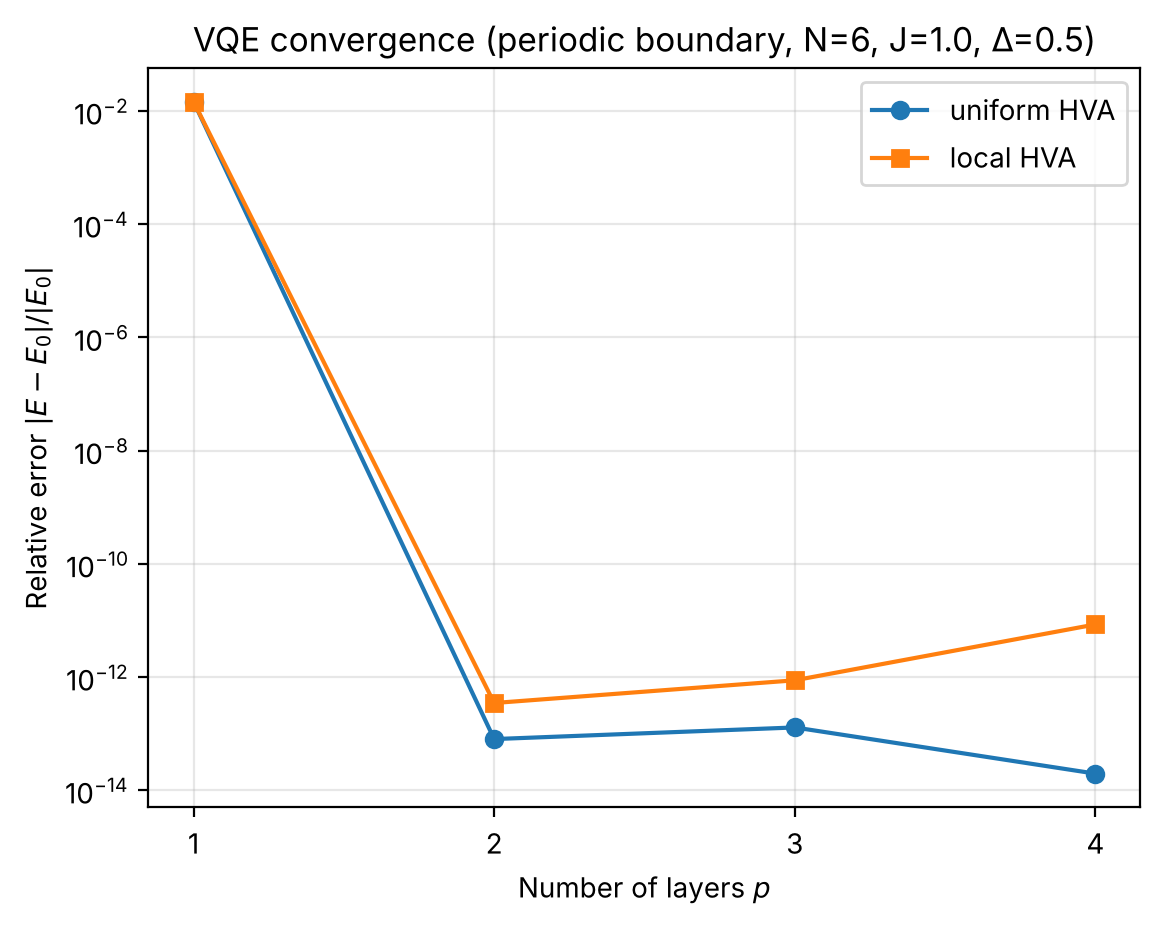

In [6]:
N = 6
J = 1.0
Delta = 0.5
p_max = 4
compare_hva(N, J, Delta, p_max, pbc=True)

一様なHVAも局所的なHVAも、$p=2$層で厳密値に（最適化の精度で）一致する。$p=1$では2つのHVAのエネルギーは同じで、局所的なHVAにしてパラメータを増やしても改善しない。TFIMと同じく、周期境界条件では偶数ボンドどうし・奇数ボンドどうしが同等（2サイトの並進対称性）なので、ボンドごとに角度を変える必要がないからである。

- **TFIMとの違い**：TFIMの周期境界条件では$p = n/2 = 3$層が必要だったが、XXZ模型では$p=2$で足りている。XXZ模型のHVAは1層に4つのパラメータをもち、さらに出力状態が全磁化0の部分空間（$n=6$で$\binom{6}{3} = 20$次元）に制限されている。スピン反転や並進・反転の対称性も保たれるので、実際に探す必要のある状態の空間はさらに小さい。初期状態の一重項がすでに偶数ボンドの相関をもっていることも効いていると考えられる。ここでは、少ないパラメータで済むことを数値で確かめるにとどめる。

### 4.2 開放境界条件

E0 (ED, open) = -8.3915505530


uniform HVA  p=1: E = -8.2745637794  相対誤差 = 1.4e-02
uniform HVA  p=2: E = -8.3889089952  相対誤差 = 3.1e-04
uniform HVA  p=3: E = -8.3915505530  相対誤差 = 6.7e-13
uniform HVA  p=4: E = -8.3915505528  相対誤差 = 2.6e-11


local HVA    p=1: E = -8.3736784927  相対誤差 = 2.1e-03
local HVA    p=2: E = -8.3915505377  相対誤差 = 1.8e-09
local HVA    p=3: E = -8.3915505051  相対誤差 = 5.7e-09
local HVA    p=4: E = -8.3915505172  相対誤差 = 4.3e-09


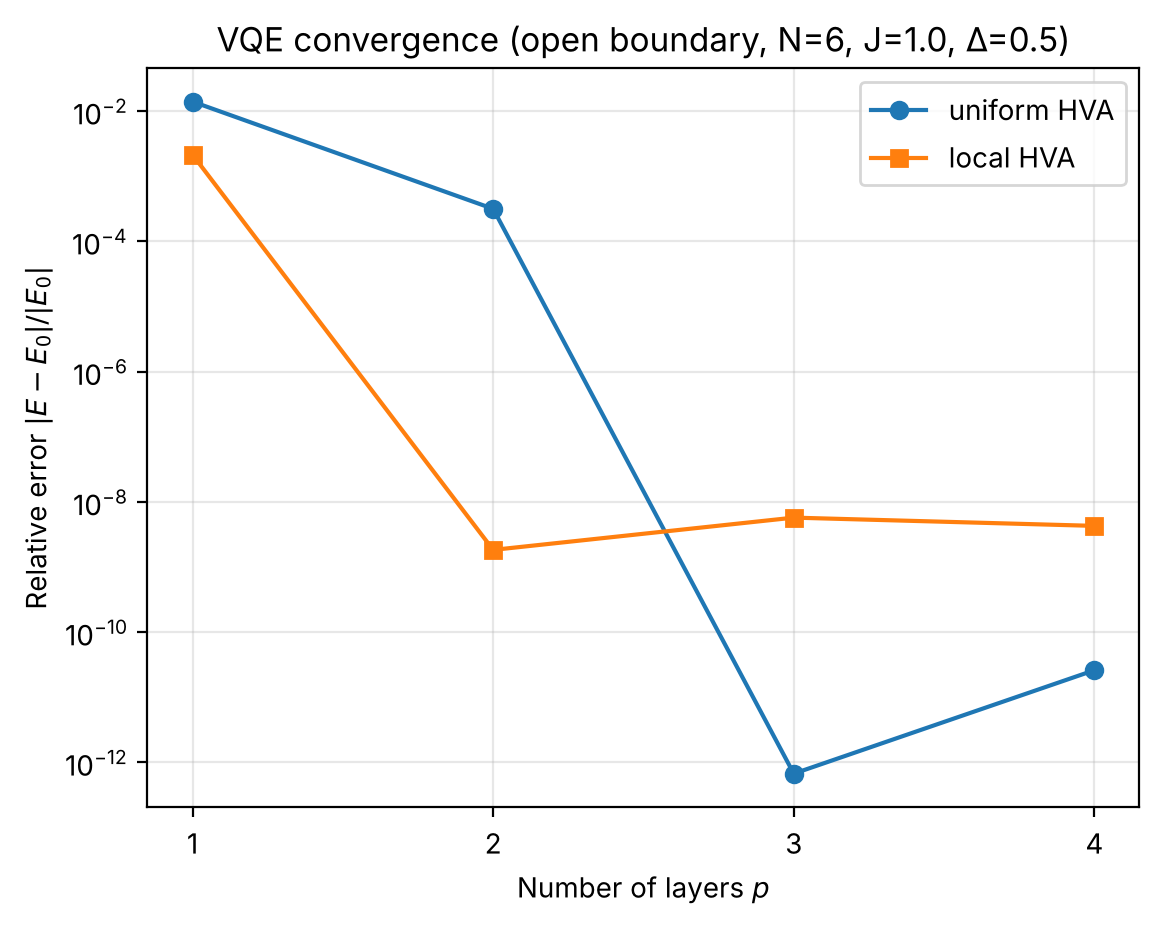

In [7]:
N = 6
J = 1.0
Delta = 0.5
p_max = 4
compare_hva(N, J, Delta, p_max, pbc=False)

局所的なHVAは$p=2$で厳密値（相対誤差は最適化の精度程度）に到達するが、一様なHVAは$p=3$まで必要になる。

- **一様なHVAの収束が遅い理由（端の効果）**：TFIMと同じく、開放境界条件では端のスピンの隣が1つしかないので、基底状態での$\langle X_jX_{j+1}\rangle$などは端と中央で異なる。一様なHVAは全ボンドに同じ角度を使うので、この違いを調整しにくい。局所的なHVAはゲートごとに角度を変えられるので、端の効果を表現できる。
- **光円錐だけでは決まらない**：一重項の初期状態から、奇数ボンド→偶数ボンドの1層をかけると、$n=6$の鎖の両端（サイト0と5）の間にも相関が届く。それでも$p=1$では厳密値に届かないので、必要な層の数は相関の届く距離ではなく、アンザッツの表現力（パラメータの数と、その動かし方）で決まっている。

## まとめ

- 厳密対角化とBethe仮説の$E_0$は数値誤差の範囲で一致する。Bethe仮説なら$n=1000$でも数秒で計算でき、熱力学極限の値（Hulthén、Yang-Yang）も確かめられる。
- 臨界相（$-1<\Delta\le1$）では、周期境界条件の$E_0/n$の有限サイズ補正が$-\pi cv/(6n^2)$（$c=1$）に一致し、共形場理論による記述が確かめられた。ギャップのある相（$\Delta>1$）では補正が指数関数的に小さい。
- 一重項から始めるHVAは、周期境界条件では一様でも局所的でも$p=2$層で厳密値に到達する。開放境界条件では、局所的なHVAは$p=2$、一様なHVAは$p=3$層が必要で、TFIMと同じく端の効果が一様なHVAの収束を遅くする。